# Producto 1 · Proyecto integrador
## Definición del problema, preparación de los datos y modelo de referencia k-NN con análisis sesgo–varianza
**Machine Learning y Deep Learning · Escuela de Posgrado – UPG de Ingeniería y Arquitectura · Universidad Peruana Unión**
**Docente:** Johann A. Ospina-Galindez

---

**Integrante:** Dr. Walter Saucedo Vega (trabajo individual)
**Repositorio:** *[enlace de GitHub]*

**Problema:** predecir la nota final (G3, escala 0–20) de estudiantes de secundaria en lengua portuguesa a partir de características demográficas, familiares y escolares, **sin usar las notas parciales** G1 y G2 (Cortez y Silva, 2008).

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEMILLA = 2026
DATA_URL = "https://raw.githubusercontent.com/avehtari/ROS-Examples/master/Student/data/student-por.csv"
# Copia pública e idéntica del archivo de UCI (Cortez, 2008), alojada en el repositorio de
# Gelman, Hill y Vehtari (2020). Alternativa: data/student-por.csv en el repositorio del proyecto.
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False})
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.5 | scikit-learn 1.9.1


## 1. Definición del problema

| Elemento | Descripción |
|---|---|
| Dominio | Educación secundaria (analítica del aprendizaje, alerta temprana) |
| Pregunta | ¿Qué tan bien se puede predecir la nota final de un estudiante en lengua portuguesa con información disponible al inicio del año (demografía, familia, hábitos y trayectoria escolar), sin usar las notas parciales? |
| Variable de respuesta | `G3`: nota final del año, escala vigesimal 0–20 (puntos) |
| Tipo de tarea | Regresión |
| Métrica principal y justificación | **RMSE** (puntos de nota): está en la unidad de la respuesta y penaliza más los errores grandes, que son los que hacen pasar por alto a un estudiante en riesgo. Complementarias: **MAE** (error típico en puntos, robusto a errores extremos) y **R²** (proporción de varianza explicada). |
| Objetivo predominante | Predicción (alerta temprana); la inferencia sobre factores queda para modelos interpretables de sesiones posteriores |
| Costo de los errores | **Sobrestimar** la nota de un estudiante que terminará desaprobando (< 10) lo deja sin tutoría: es el error más costoso. **Subestimarla** genera apoyo innecesario, con un costo menor (horas de tutoría). |

## 2. Carga y descripción de los datos
**Fuente:** UCI Machine Learning Repository, *Student Performance* (Cortez, 2008), https://doi.org/10.24432/C5TG7T. Licencia **CC BY 4.0**. Datos recogidos mediante registros escolares y cuestionarios en dos escuelas públicas de Portugal (2005–2006); no contienen nombres ni identificadores personales. Se usa el subconjunto de **lengua portuguesa** (649 estudiantes, 30 predictores); el de matemáticas tiene solo 395 y no cumple el mínimo de 500.

**Decisiones de alcance (antes de cualquier modelado):**
- Se excluyen `G1` y `G2` (notas del 1.er y 2.º periodo): están muy correlacionadas con `G3` y no se conocen al inicio del año; incluirlas sería fuga de información.
- Se excluyen los 15 estudiantes con `G3 = 0`: en esta escala una nota de 0 no corresponde a un desempeño evaluado, sino a estudiantes que no rindieron la evaluación final (abandono). Es un fenómeno distinto, que merece su propio modelo de clasificación. La población objetivo queda definida como *estudiantes que completan el año*.

In [2]:
df_raw = pd.read_csv(DATA_URL, sep=";")
print("Datos originales:", df_raw.shape)

df = df_raw.drop(columns=["G1", "G2"])            # evitar fuga de información
n_ceros = (df["G3"] == 0).sum()
df = df[df["G3"] > 0].reset_index(drop=True)      # excluir abandonos (G3 = 0)
RESPUESTA = "G3"
print(f"Estudiantes con G3 = 0 excluidos: {n_ceros}")
print("Datos para el modelado:", df.shape, f"→ {df.shape[1] - 1} predictores")
df.head()

Datos originales: (649, 33)
Estudiantes con G3 = 0 excluidos: 15
Datos para el modelado: (634, 31) → 30 predictores


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,4,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,2,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,6,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,0,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,0,13


In [3]:
DESCRIPCION = {
 "school": [
  "categórica",
  "-",
  "Escuela: GP = Gabriel Pereira, MS = Mousinho da Silveira"
 ],
 "sex": [
  "categórica",
  "-",
  "Sexo del estudiante: F / M"
 ],
 "age": [
  "numérica",
  "años",
  "Edad (15–22)"
 ],
 "address": [
  "categórica",
  "-",
  "Zona del domicilio: U = urbana, R = rural"
 ],
 "famsize": [
  "categórica",
  "-",
  "Tamaño de la familia: LE3 = ≤ 3, GT3 = > 3"
 ],
 "Pstatus": [
  "categórica",
  "-",
  "Convivencia de los padres: T = juntos, A = separados"
 ],
 "Medu": [
  "ordinal",
  "0–4",
  "Educación de la madre (0 = ninguna … 4 = superior)"
 ],
 "Fedu": [
  "ordinal",
  "0–4",
  "Educación del padre (0 = ninguna … 4 = superior)"
 ],
 "Mjob": [
  "categórica",
  "-",
  "Ocupación de la madre (docente, salud, servicios, hogar, otra)"
 ],
 "Fjob": [
  "categórica",
  "-",
  "Ocupación del padre (docente, salud, servicios, hogar, otra)"
 ],
 "reason": [
  "categórica",
  "-",
  "Motivo de elección de la escuela (cercanía, reputación, curso, otro)"
 ],
 "guardian": [
  "categórica",
  "-",
  "Apoderado: madre, padre u otro"
 ],
 "traveltime": [
  "ordinal",
  "1–4",
  "Tiempo de viaje a la escuela (1 = < 15 min … 4 = > 1 h)"
 ],
 "studytime": [
  "ordinal",
  "1–4",
  "Horas de estudio semanales (1 = < 2 h … 4 = > 10 h)"
 ],
 "failures": [
  "numérica",
  "cursos",
  "Número de cursos desaprobados previamente (0–3; 3 = 3 o más)"
 ],
 "schoolsup": [
  "binaria",
  "sí/no",
  "Apoyo educativo adicional de la escuela"
 ],
 "famsup": [
  "binaria",
  "sí/no",
  "Apoyo educativo de la familia"
 ],
 "paid": [
  "binaria",
  "sí/no",
  "Clases particulares pagadas en la asignatura"
 ],
 "activities": [
  "binaria",
  "sí/no",
  "Actividades extracurriculares"
 ],
 "nursery": [
  "binaria",
  "sí/no",
  "Asistió a educación inicial"
 ],
 "higher": [
  "binaria",
  "sí/no",
  "Desea seguir estudios superiores"
 ],
 "internet": [
  "binaria",
  "sí/no",
  "Acceso a internet en casa"
 ],
 "romantic": [
  "binaria",
  "sí/no",
  "Tiene una relación sentimental"
 ],
 "famrel": [
  "ordinal",
  "1–5",
  "Calidad de las relaciones familiares (1 = muy mala … 5 = excelente)"
 ],
 "freetime": [
  "ordinal",
  "1–5",
  "Tiempo libre después de clases (1 = muy poco … 5 = mucho)"
 ],
 "goout": [
  "ordinal",
  "1–5",
  "Frecuencia de salidas con amigos"
 ],
 "Dalc": [
  "ordinal",
  "1–5",
  "Consumo de alcohol en días laborables"
 ],
 "Walc": [
  "ordinal",
  "1–5",
  "Consumo de alcohol en fin de semana"
 ],
 "health": [
  "ordinal",
  "1–5",
  "Estado de salud autorreportado (1 = muy malo … 5 = muy bueno)"
 ],
 "absences": [
  "numérica",
  "días",
  "Número de inasistencias (0–32)"
 ],
 "G3": [
  "numérica",
  "puntos",
  "RESPUESTA: nota final del año (1–19 tras excluir los 0)"
 ]
}

diccionario = pd.DataFrame({"variable": df.columns, "tipo_pandas": df.dtypes.astype(str).values,
                            "faltantes": df.isna().sum().values, "valores_unicos": df.nunique().values})
diccionario["tipo"] = diccionario.variable.map(lambda v: DESCRIPCION[v][0])
diccionario["unidad"] = diccionario.variable.map(lambda v: DESCRIPCION[v][1])
diccionario["descripcion"] = diccionario.variable.map(lambda v: DESCRIPCION[v][2])
pd.set_option("display.max_colwidth", 90)
diccionario

,variable,tipo_pandas,faltantes,valores_unicos,tipo,unidad,descripcion
0,school,str,0,2,categórica,-,"Escuela: GP = Gabriel Pereira, MS = Mousinho da Silveira"
1,sex,str,0,2,categórica,-,Sexo del estudiante: F / M
2,age,int64,0,8,numérica,años,Edad (15–22)
3,address,str,0,2,categórica,-,"Zona del domicilio: U = urbana, R = rural"
4,famsize,str,0,2,categórica,-,"Tamaño de la familia: LE3 = ≤ 3, GT3 = > 3"
5,Pstatus,str,0,2,categórica,-,"Convivencia de los padres: T = juntos, A = separados"
6,Medu,int64,0,5,ordinal,0–4,Educación de la madre (0 = ninguna … 4 = superior)
7,Fedu,int64,0,5,ordinal,0–4,Educación del padre (0 = ninguna … 4 = superior)
8,Mjob,str,0,5,categórica,-,"Ocupación de la madre (docente, salud, servicios, hogar, otra)"
9,Fjob,str,0,5,categórica,-,"Ocupación del padre (docente, salud, servicios, hogar, otra)"


## 3. Análisis exploratorio orientado a decisiones

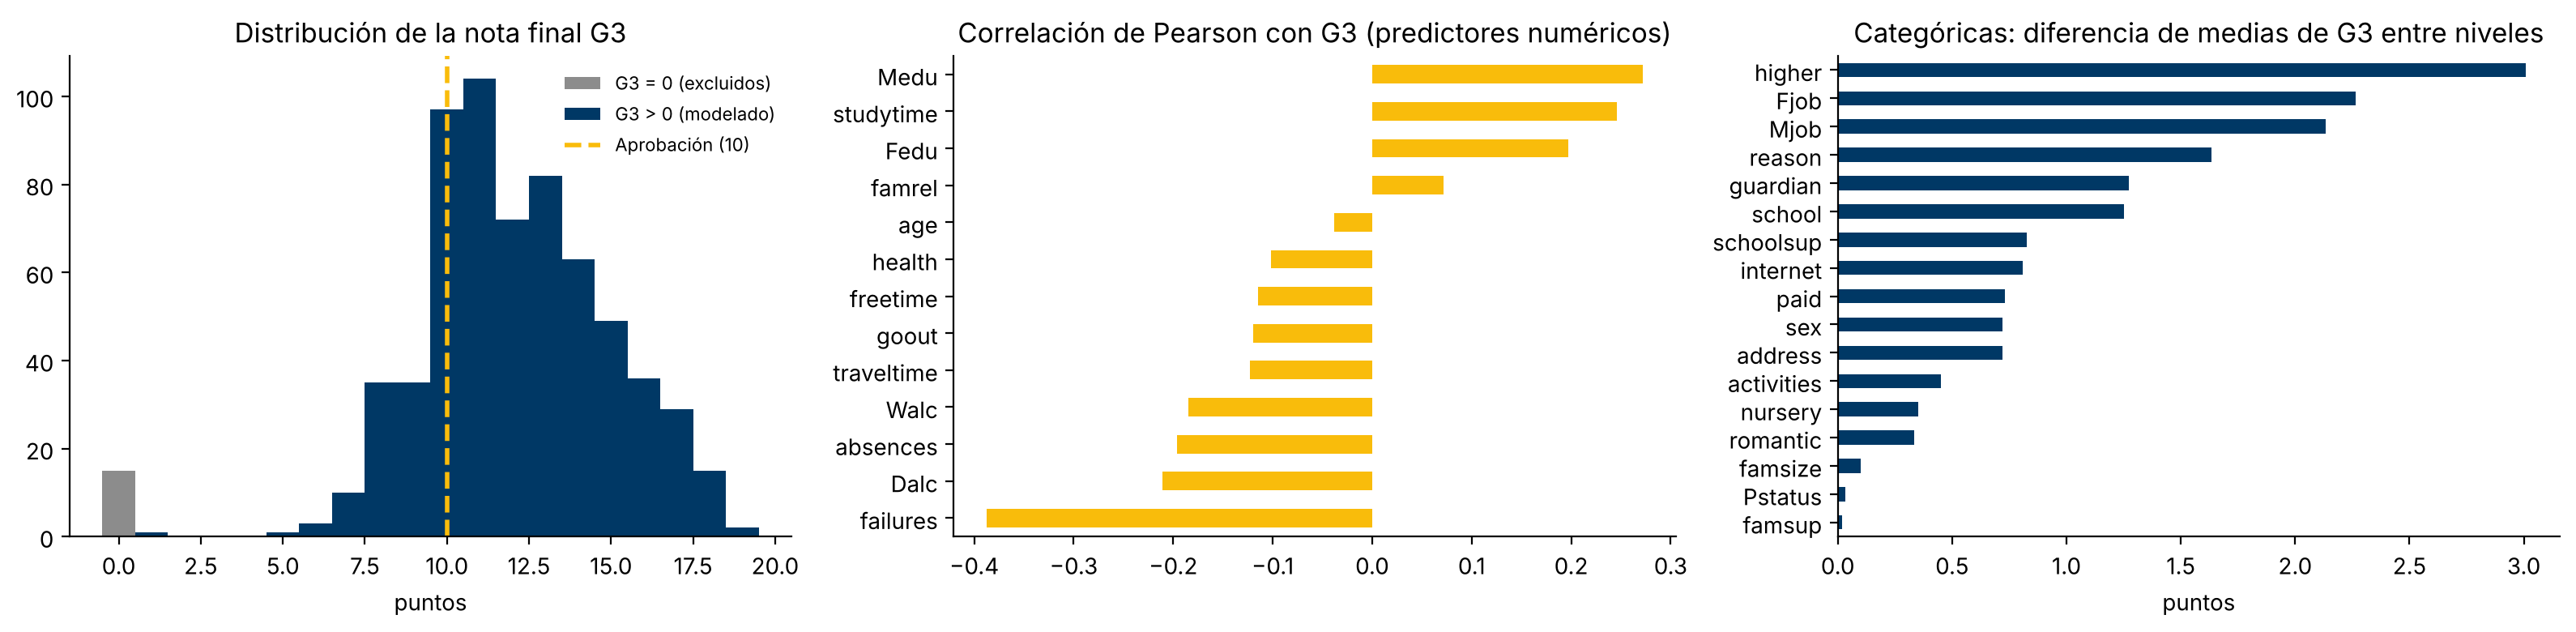

G3: media = 12.19, DE = 2.69, % desaprobados (< 10) = 13.4 %
Valores faltantes totales: 0
Inasistencias: mediana = 2.0 | máx = 32 | asimetría = 2.0
Fallas previas (failures): {0: 543, 1: 63, 2: 15, 3: 13}
Niveles por variable categórica: {'school': 2, 'sex': 2, 'address': 2, 'famsize': 2, 'Pstatus': 2, 'Mjob': 5, 'Fjob': 5, 'reason': 4, 'guardian': 3, 'schoolsup': 2, 'famsup': 2, 'paid': 2, 'activities': 2, 'nursery': 2, 'higher': 2, 'internet': 2, 'romantic': 2}


,count,mean,std,min,25%,50%,75%,max
age,634.0,16.72,1.21,15.0,16.0,17.0,18.0,22.0
Medu,634.0,2.52,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,634.0,2.32,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,634.0,1.56,0.75,1.0,1.0,1.0,2.0,4.0
studytime,634.0,1.94,0.83,1.0,1.0,2.0,2.0,4.0
failures,634.0,0.21,0.58,0.0,0.0,0.0,0.0,3.0
famrel,634.0,3.93,0.95,1.0,4.0,4.0,5.0,5.0
freetime,634.0,3.17,1.05,1.0,3.0,3.0,4.0,5.0
goout,634.0,3.19,1.16,1.0,2.0,3.0,4.0,5.0
Dalc,634.0,1.49,0.92,1.0,1.0,1.0,2.0,5.0


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].hist(df_raw["G3"], bins=np.arange(-0.5, 20.5, 1), color="#8C8C8C", label="G3 = 0 (excluidos)")
axs[0].hist(df[RESPUESTA], bins=np.arange(-0.5, 20.5, 1), color="#003865", label="G3 > 0 (modelado)")
axs[0].axvline(10, color="#F9BC0B", ls="--", lw=2, label="Aprobación (10)")
axs[0].set_title("Distribución de la nota final G3"); axs[0].set_xlabel("puntos"); axs[0].legend(frameon=False, fontsize=8)

num = df.select_dtypes("number").drop(columns=RESPUESTA)
num.corrwith(df[RESPUESTA]).sort_values().plot.barh(ax=axs[1], color="#F9BC0B")
axs[1].set_title("Correlación de Pearson con G3 (predictores numéricos)")

cat = df.select_dtypes(exclude="number").columns
dif = pd.Series({c: df.groupby(c)[RESPUESTA].mean().max() - df.groupby(c)[RESPUESTA].mean().min() for c in cat}).sort_values()
dif.plot.barh(ax=axs[2], color="#003865")
axs[2].set_title("Categóricas: diferencia de medias de G3 entre niveles"); axs[2].set_xlabel("puntos")
plt.tight_layout(); plt.savefig("fig1_eda.png", dpi=200, bbox_inches="tight"); plt.show()

print(f"G3: media = {df[RESPUESTA].mean():.2f}, DE = {df[RESPUESTA].std():.2f}, "
      f"% desaprobados (< 10) = {100 * (df[RESPUESTA] < 10).mean():.1f} %")
print("Valores faltantes totales:", df.isna().sum().sum())
print("Inasistencias: mediana =", df.absences.median(), "| máx =", df.absences.max(),
      "| asimetría =", round(df.absences.skew(), 2))
print("Fallas previas (failures):", df.failures.value_counts().sort_index().to_dict())
print("Niveles por variable categórica:", {c: df[c].nunique() for c in cat})
df.describe().T.round(2)

**Hallazgos y decisiones.**

| Hallazgo | Decisión |
|---|---|
| `G1` y `G2` están muy correlacionadas con `G3`, pero se conocen solo durante el año | Excluirlas para evitar fuga de información; el modelo debe predecir al inicio del año |
| 15 estudiantes (2.3 %) con `G3 = 0`, separados del resto de la distribución (abandono, no nota evaluada) | Excluirlos y definir la población como *estudiantes que completan el año* (n = 634) |
| `G3` es aproximadamente simétrica (media 12.2, DE 2.7); el 13.4 % desaprueba (< 10) | Regresión con pérdida cuadrática; RMSE como métrica principal y MAE como complementaria. Partición sin estratificar (no es clasificación), verificando que las medias de `G3` sean similares en las tres particiones |
| 17 variables categóricas (13 binarias, 4 con 3–5 niveles) | Codificación one-hot con `drop_first`: 30 predictores pasan a ser 39 columnas |
| Predictores en escalas muy distintas (`absences` 0–32; ordinales 1–5; binarias 0/1) | Estandarización ajustada solo con entrenamiento: indispensable en el k-NN, que usa distancias euclidianas |
| `absences` es asimétrica (mediana 2, máximo 32, asimetría 2.0) | Se conserva sin recortar (los valores altos son plausibles); se documenta que pueden pesar en la distancia |
| Asociaciones débiles: la más fuerte es `failures` (r = −0.39), seguida de `Medu` (0.27) y `studytime` (0.25); entre las categóricas destaca `higher` (≈ 3 puntos de diferencia) | Se espera una mejora modesta sobre el modelo trivial; muchos predictores poco informativos degradarán las distancias del k-NN |
| Sin valores faltantes | Se mantiene un imputador por mediana dentro del flujo, ajustado con entrenamiento, por robustez |

## 4. Particiones: entrenamiento (60 %), validación (20 %) y prueba (20 %)
Las particiones se realizan **antes** de cualquier transformación que aprenda de los datos. En clasificación, agregue `stratify` en ambas llamadas.

In [5]:
X = pd.get_dummies(df.drop(columns=RESPUESTA), drop_first=True, dtype=float)   # codificación one-hot
y = df[RESPUESTA]
print(f"Predictores tras la codificación one-hot: {X.shape[1]}")

def particionar(X, y, semilla):
    X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, random_state=semilla)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=semilla)  # 0.25 × 0.80 = 0.20
    return X_tr, X_va, X_te, y_tr, y_va, y_te

X_tr, X_va, X_te, y_tr, y_va, y_te = particionar(X, y, SEMILLA)
print(f"Entrenamiento: {X_tr.shape} | Validación: {X_va.shape} | Prueba: {X_te.shape}")
print(f"Media de G3 → entrenamiento {y_tr.mean():.2f} | validación {y_va.mean():.2f} | prueba {y_te.mean():.2f}")

Predictores tras la codificación one-hot: 39
Entrenamiento: (380, 39) | Validación: (127, 39) | Prueba: (127, 39)
Media de G3 → entrenamiento 12.23 | validación 12.30 | prueba 11.94


## 5. Preparación: imputación y estandarización
Las transformaciones se **ajustan solo con el conjunto de entrenamiento** (`fit`) y luego se aplican a validación y prueba (`transform`). Si se ajustaran con todos los datos, la información de validación y prueba se filtraría al modelo.

El conjunto no tiene valores faltantes, pero se conserva el imputador por mediana para que el flujo sea robusto ante datos nuevos incompletos. Las variables ordinales (p. ej., `Medu`, `studytime`) se tratan como numéricas y también se estandarizan.

In [6]:
def preparar(X_tr, *otros):
    imputador = SimpleImputer(strategy="median").fit(X_tr)
    escalador = StandardScaler().fit(imputador.transform(X_tr))
    f = lambda Z: escalador.transform(imputador.transform(Z))
    return [f(X_tr)] + [f(Z) for Z in otros]

Z_tr, Z_va, Z_te = preparar(X_tr, X_va, X_te)
print("Medias en entrenamiento (≈ 0):", Z_tr.mean(0).round(2)[:5])
print("Medias en validación (≠ 0):   ", Z_va.mean(0).round(2)[:5])

Medias en entrenamiento (≈ 0): [-0.  0.  0.  0. -0.]
Medias en validación (≠ 0):    [-0.08  0.05  0.1   0.07  0.15]


## 6. Modelos de referencia

### 6.1 Modelo trivial
Clasificación: `DummyClassifier(strategy="most_frequent")`.

In [7]:
trivial = DummyRegressor(strategy="mean").fit(Z_tr, y_tr)

### 6.2 Selección de k con el conjunto de validación
Clasificación: `KNeighborsClassifier` y tasa de error `1 - accuracy_score(y, y_pred)`.

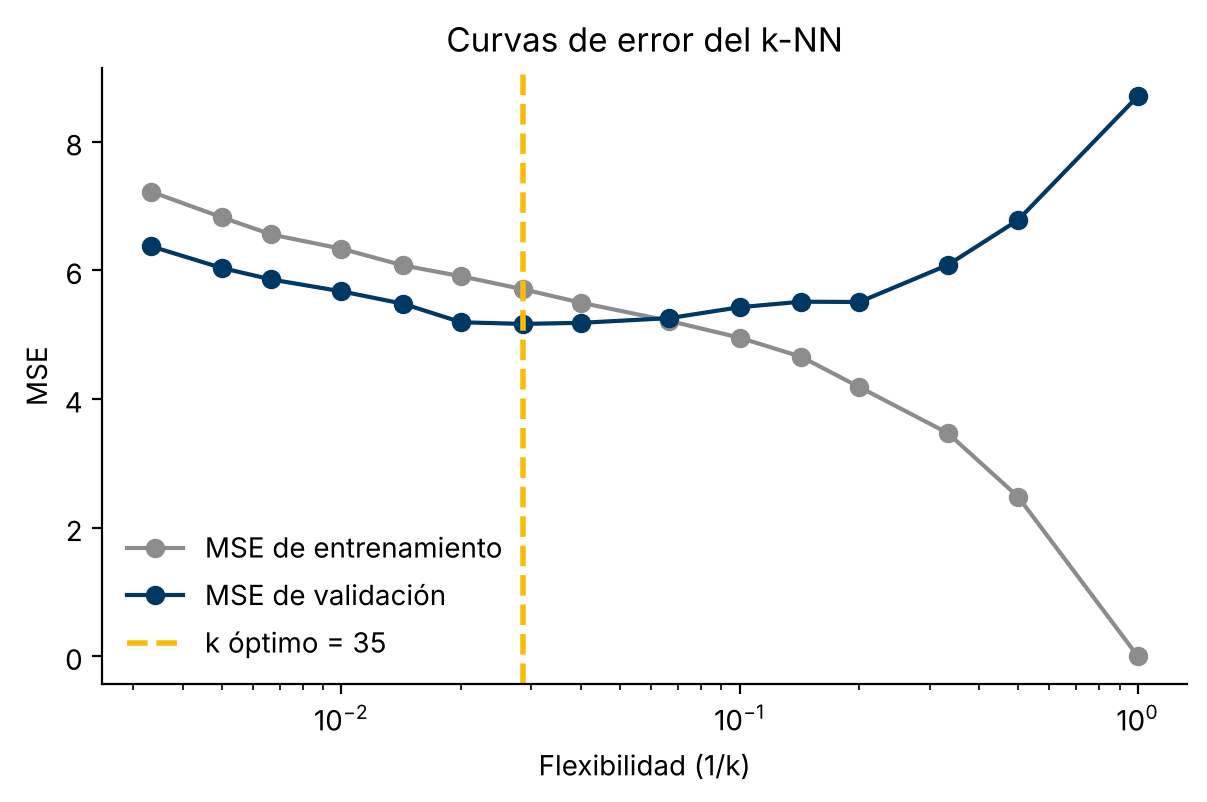

k óptimo: 35 | MSE de validación mínimo: 5.17 (RMSE = 2.27)
MSE de validación del modelo trivial: 6.70


,k,MSE_entrenamiento,MSE_validacion
0,300,7.22,6.37
1,200,6.83,6.04
2,150,6.56,5.86
3,100,6.34,5.67
4,70,6.08,5.48
5,50,5.91,5.19
6,35,5.71,5.17
7,25,5.50,5.18
8,15,5.21,5.26
9,10,4.95,5.43


In [8]:
ks = np.array([300, 200, 150, 100, 70, 50, 35, 25, 15, 10, 7, 5, 3, 2, 1])

def curvas_knn(Z_tr, y_tr, Z_va, y_va, ks):
    err_tr, err_va = [], []
    for k in ks:
        m = KNeighborsRegressor(n_neighbors=int(k)).fit(Z_tr, y_tr)
        err_tr.append(mean_squared_error(y_tr, m.predict(Z_tr)))
        err_va.append(mean_squared_error(y_va, m.predict(Z_va)))
    return np.array(err_tr), np.array(err_va)

ks = ks[ks < len(Z_tr)]
err_tr, err_va = curvas_knn(Z_tr, y_tr, Z_va, y_va, ks)
k_opt = int(ks[np.argmin(err_va)])

plt.plot(1 / ks, err_tr, "-o", color="#8C8C8C", label="MSE de entrenamiento")
plt.plot(1 / ks, err_va, "-o", color="#003865", label="MSE de validación")
plt.axvline(1 / k_opt, color="#F9BC0B", ls="--", lw=2, label=f"k óptimo = {k_opt}")
plt.xscale("log"); plt.xlabel("Flexibilidad (1/k)"); plt.ylabel("MSE"); plt.legend(frameon=False)
plt.title("Curvas de error del k-NN"); plt.savefig("fig2_curvas.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"k óptimo: {k_opt} | MSE de validación mínimo: {err_va.min():.2f} (RMSE = {err_va.min() ** 0.5:.2f})")
print(f"MSE de validación del modelo trivial: {mean_squared_error(y_va, trivial.predict(Z_va)):.2f}")
pd.DataFrame({"k": ks, "MSE_entrenamiento": err_tr, "MSE_validacion": err_va}).round(2)

**Interpretación.**

La curva de validación tiene forma de U aplanada con mínimo en **k = 35** (MSE = 5.17; RMSE = 2.27 puntos), frente a un MSE de 6.70 del modelo trivial en la misma partición. **Zona de subajuste** (k ≥ 70, izquierda): el k-NN promedia tantos estudiantes que sus predicciones se acercan a la media global; el sesgo domina y ambos errores son altos (k = 300: MSE de validación 6.37). **Zona de sobreajuste** (k ≤ 10, derecha): el error de entrenamiento sigue bajando, pero el de validación sube hasta 8.71 con k = 1, porque cada predicción depende de unos pocos vecinos y la varianza domina. Con **k = 1 el MSE de entrenamiento es cero** porque cada estudiante de entrenamiento es su propio vecino más cercano (distancia cero) y el modelo devuelve exactamente su nota: memoriza la muestra, ruido incluido. El valle es ancho (k = 25 a 50 dan MSE entre 5.17 y 5.19), lo que indica que la elección exacta de k importa poco dentro de ese rango. Que el error de validación quede por debajo del de entrenamiento con k grande no contradice la teoría: refleja que esta partición de validación tiene menor dispersión de `G3` que la de entrenamiento (varianza 6.70 frente a 7.62), una manifestación de la variabilidad analizada en 6.3.

### 6.3 Variabilidad del k óptimo entre particiones
Se repite todo el procedimiento (particiones, preparación y selección de k) con cinco semillas distintas.

In [9]:
filas = []
for semilla in [1, 2, 3, 4, 5]:
    a_tr, a_va, _, b_tr, b_va, _ = particionar(X, y, semilla)
    za_tr, za_va = preparar(a_tr, a_va)
    _, e_va = curvas_knn(za_tr, b_tr, za_va, b_va, ks)
    filas.append({"semilla": semilla, "k_optimo": int(ks[np.argmin(e_va)]), "MSE_validacion_min": e_va.min(),
                  "MSE_validacion_trivial": mean_squared_error(b_va, np.full(len(b_va), b_tr.mean()))})
variabilidad = pd.DataFrame(filas).round(2)
print(f"k óptimo: de {variabilidad.k_optimo.min()} a {variabilidad.k_optimo.max()}")
variabilidad

k óptimo: de 7 a 50


,semilla,k_optimo,MSE_validacion_min,MSE_validacion_trivial
0,1,7,4.22,5.66
1,2,15,6.05,8.20
2,3,7,5.77,7.92
3,4,50,5.50,6.96
4,5,15,7.17,8.12


**Interpretación.**

La variabilidad es grande: el k óptimo va de **7 a 50** según la semilla (7, 15, 7, 50, 15) y el MSE de validación mínimo, de **4.22 a 7.17**. Además, el MSE del modelo trivial cambia casi lo mismo (5.66 a 8.20), lo que muestra que buena parte de la variación se debe a qué estudiantes caen en validación y no al modelo. Con solo 127 observaciones de validación, una partición única entrega una estimación ruidosa del error; como la curva es plana entre k ≈ 7 y 50, pequeñas fluctuaciones mueven el mínimo de un extremo al otro del valle. Por lo tanto, el k = 35 elegido con la semilla 2026 no debe tomarse como «el» valor óptimo, sino como uno de los valores razonables. Promediar el error sobre varias particiones —validación cruzada k-fold, Unidad III— daría una selección más estable y permitiría reportar la incertidumbre del error.

## 7. Evaluación en el conjunto de prueba (una sola vez)
Clasificación: tasa de error, exactitud balanceada y matriz de confusión (`sklearn.metrics`).

In [10]:
knn = KNeighborsRegressor(n_neighbors=k_opt).fit(Z_tr, y_tr)

def metricas(modelo, Z, y):
    p = modelo.predict(Z)
    return {"MSE": mean_squared_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
            "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

resultados = pd.DataFrame({"Trivial (media)": metricas(trivial, Z_te, y_te),
                           f"k-NN (k = {k_opt})": metricas(knn, Z_te, y_te)}).T.round(3)
resultados
display(resultados)

mejora = 100 * (1 - resultados.iloc[1]["RMSE"] / resultados.iloc[0]["RMSE"])
print(f"Reducción del RMSE del k-NN frente al trivial: {mejora:.1f} %")

# Costo asimétrico: estudiantes que desaprueban (G3 < 10) a los que el modelo les predice aprobación
p_te = knn.predict(Z_te)
riesgo = y_te.values < 10
print(f"Desaprobados en prueba: {riesgo.sum()} | el k-NN les predice ≥ 10 a {(p_te[riesgo] >= 10).sum()}")
print(f"Rango de predicciones del k-NN: {p_te.min():.1f} a {p_te.max():.1f} (G3 real: {y_te.min()} a {y_te.max()})")

,MSE,RMSE,MAE,R2
Trivial (media),6.636,2.576,2.121,-0.013
k-NN (k = 35),5.667,2.381,1.937,0.134


Reducción del RMSE del k-NN frente al trivial: 7.6 %
Desaprobados en prueba: 19 | el k-NN les predice ≥ 10 a 19
Rango de predicciones del k-NN: 10.3 a 14.1 (G3 real: 6 a 18)


## 9. Discusión

**1. Mejora frente al modelo trivial.** En prueba, el k-NN (k = 35) obtiene un RMSE de 2.38 puntos frente a 2.58 del modelo trivial, una reducción del 7.6 %; el MAE baja de 2.12 a 1.94 y el R² apenas llega a 0.13. En el dominio, la mejora es poco relevante: el k-NN predice notas entre 10.3 y 14.1 cuando las reales van de 6 a 18, y **a los 19 estudiantes de prueba que desaprobaron les predice aprobación**. Para alerta temprana, el modelo todavía no sirve: comete justamente el error más costoso.

**2. Sesgo–varianza.** Las curvas muestran el patrón esperado (subajuste con k grande, sobreajuste con k pequeño), pero el valle es ancho y el error mínimo queda cerca del trivial: con estos predictores, la mayor parte del error parece irreducible o no capturable por similitud en 39 dimensiones. La variabilidad del k óptimo (7 a 50) indica que la partición pesa tanto como el hiperparámetro y que el k elegido con una sola partición es poco confiable.

**3. Limitaciones y próximos pasos.** El k-NN trata por igual las 39 columnas: las pocas informativas (`failures`, `higher`, `Medu`, `studytime`) se diluyen entre muchas irrelevantes, y en alta dimensión las distancias pierden contraste. Tampoco es interpretable ni indica qué factores importan, y cada predicción exige calcular distancias a todo el entrenamiento. En las próximas sesiones espero mejorar con regresión lineal y regularizada (Lasso/Ridge), que seleccionan o ponderan predictores y ofrecen coeficientes interpretables; con validación cruzada para elegir hiperparámetros; y explorar una formulación de clasificación del riesgo (G3 < 10) con una métrica centrada en detectar a los desaprobados.

## 10. Reproducibilidad
Genere el archivo `requirements.txt` para el repositorio:

In [11]:
print(f"numpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\nmatplotlib=={plt.matplotlib.__version__}")

numpy==2.5.3
pandas==3.0.5
scikit-learn==1.9.1
matplotlib==3.11.2


## Referencias
- Cortez, P. (2008). *Student performance* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T
- Cortez, P., & Silva, A. M. G. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)* (pp. 5–12). EUROSIS.
- Gelman, A., Hill, J., & Vehtari, A. (2020). *Regression and other stories*. Cambridge University Press. *(Repositorio de ejemplos del que se carga la copia del archivo.)*
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning* (2.ª ed., secs. 2.3 y 7.3). Springer. https://doi.org/10.1007/978-0-387-84858-7
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python* (cap. 2). Springer. https://doi.org/10.1007/978-3-031-38747-0
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

**Uso de IA generativa:** se utilizó Claude (Anthropic) como apoyo para estructurar el código a partir de la plantilla y para revisar la redacción; el análisis, las decisiones y su verificación son responsabilidad del autor.